In [2]:
import pandas as pd
import numpy as np
df = pd.read_csv('spam.csv',encoding='latin-1')
df.head()
#df.info()



,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
df.drop(columns=['Unnamed: 2','Unnamed: 3','Unnamed: 4'],inplace= True)
df.sample(5)  #Return a random sample of items from an axis of object.


,v1,v2
1663,ham,S but mostly not like that.
32,ham,K tell me anything about you.
3384,ham,Ok can...
3245,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
3548,ham,"I got like $ &lt;#&gt; , I can get some more l..."


In [4]:
from sklearn.preprocessing import LabelEncoder
encoder =LabelEncoder()
df['v1']=encoder.fit_transform(df['v1'])
df['v1'].sample(5)



,v1
129,0
105,0
4935,0
4922,0
1989,0


In [5]:
df.isnull().sum()
df.duplicated().sum()
df= df.drop_duplicates()

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
df['v1'].value_counts() #Return a Series containing the frequency of each distinct row in the Dataframe.


,count
v1,
0,4516
1,653


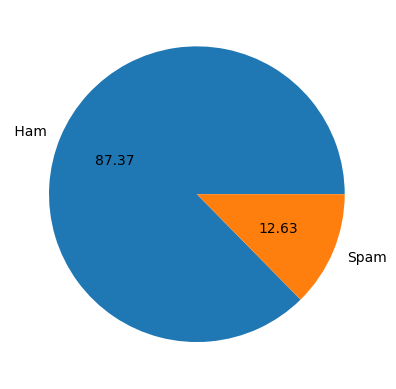

In [7]:
plt.pie(df['v1'].value_counts(),labels=[' Ham','Spam'],autopct='%0.2f')
#To add percentages to each of the constitutents of the pie chart,add autopct='%1.1f%%', to the plt.pie() function.
#This formats the percentage to the tenth place.
# to format the percentage to the hundredths place,  use the statement, autopct='%1.2f%%'
# to format the percentage to the thousandths place,  use the statement, autopct='%1.3f%%'
plt.show()

In [8]:
import nltk
nltk.download('punkt')

df['num_characters']=df['v2'].apply(len)
#to apply a function along an axis of the DataFrame.
#Objects passed to the function are Series objects whose index is either the DataFrame’s index (axis=0) or the DataFrame’s columns (axis=1). By default (result_type=None)
df['num_characters'].sample(5)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


,num_characters
4836,42
4937,129
5336,126
3551,25
4874,85


In [9]:
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
df['v2'].apply(lambda x: nltk.word_tokenize(x))
df['ascii']=df['v1'].apply(lambda x:ord(str(x)))
df.sample(5)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,v1,v2,num_characters,ascii
5016,1,Dear 0776xxxxxxx U've been invited to XCHAT. T...,154,49
2581,0,Yup i'm elaborating on the safety aspects and ...,65,48
951,0,Shb b ok lor... Thanx...,24,48
32,0,K tell me anything about you.,29,48
75,0,I am waiting machan. Call me once you free.,43,48


In [10]:
df.drop(columns=['ascii'],inplace= True)

In [11]:
df['num_words']=df['v2'].apply(lambda x:len(nltk.word_tokenize(x)))
df.sample(2)

,v1,v2,num_characters,num_words
4984,0,Dont let studying stress you out. L8r.,38,9
4817,0,How's ur paper?,15,5


In [12]:
#for ham messages
df[df['v1']==0][['num_characters','num_words']].describe()

#for ham messages
#df[df['v1']==0][['num_characters','num_words','num_sentences']].describe()
# for spam messages
#df[df['v1']==1][['num_characters','num_words','num_sentences']].describe()



,num_characters,num_words
count,4516.000000,4516.000000
mean,70.459256,17.123782
std,56.358207,13.493970
min,2.000000,1.000000
25%,34.000000,8.000000
50%,52.000000,13.000000
75%,90.000000,22.000000
max,910.000000,220.000000


In [13]:
# for spam messages
df[df['v1']==1][['num_characters','num_words']].describe()

,num_characters,num_words
count,653.000000,653.000000
mean,137.891271,27.667688
std,30.137753,7.008418
min,13.000000,2.000000
25%,132.000000,25.000000
50%,149.000000,29.000000
75%,157.000000,32.000000
max,224.000000,46.000000


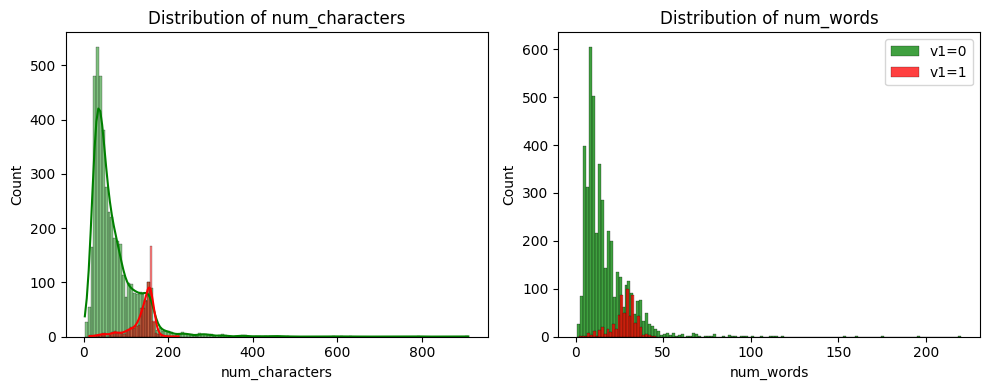

In [23]:
fig, (g1, g2) = plt.subplots(1, 2, figsize=(10, 4))

# Left subplot: num_characters
sns.histplot(df[df['v1'] == 0]['num_characters'], color='green', ax=g1, kde=True)
sns.histplot(df[df['v1'] == 1]['num_characters'], color='red', ax=g1, kde=True)
g1.set_title('Distribution of num_characters')
#g1.legend()

# Right subplot: num_words
sns.histplot(df[df['v1'] == 0]['num_words'], color='green', ax=g2, label='v1=0')
sns.histplot(df[df['v1'] == 1]['num_words'], color='red', ax=g2, label='v1=1')
g2.set_title('Distribution of num_words')
g2.legend()

plt.tight_layout()
plt.show()


In [24]:
sns.heatmap(df.corr(),annot=True)
plt.show()


ValueError: could not convert string to float: 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'

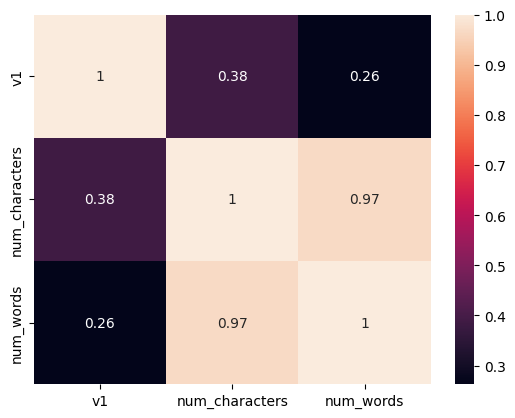

In [25]:
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True)
plt.show()

In [ ]:
def text_transform(message):
    message=message.lower() #change to lowercase
    message=nltk.word_tokenize(message)
    y=[]


    #for checking punctuations and stopwords
    for i in message:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    message=y[:]
    y.clear()

    #now stemming function
    for i in message:
        y.append(ps.stem(i))

    #return y  --> returns as list
    return " ".join(y)
# Removing stop words and punctuations
nltk.download('stopwords')
from nltk.corpus import stopwords
stopwords.words('english')
print(len(stopwords.words('english')))

#now for punctuation
import string
string.punctuation
# stemming
from nltk.stem.porter import PorterStemmer
ps =PorterStemmer()

df['transformed_msg']=df['v2'].apply(text_transform)
df.sample(3)

In [5]:
import string
print(string.punctuation)
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stopwords.words('english')
#print(stopwords.words('english'))

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kanma\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf= TfidfVectorizer(max_features=3000)
X=tfidf.fit_transform(df['transformed_msg']).toarray()
y=df['v1'].values

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
gnb = GaussianNB()
bnb = BernoulliNB()
mnb = MultinomialNB()

gnb.fit(X_train,y_train)
y_pred1= gnb.predict(X_test)
print('Accuracy score of Gaussian NB is: ',accuracy_score(y_test,y_pred1))
print('Confusion Matrix of Guassian NB is: ',confusion_matrix(y_test,y_pred1))
print('Precision score of the Gaussian NB is',precision_score(y_test,y_pred1))
